In [13]:
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

pd.set_option("display.max_columns", 100)

In [14]:
FEATURE_PATH = "../datamart/gold/feature_store/gold_feature_store.parquet"
LABEL_PATH = "../datamart/gold/label_store/"

features = pd.read_parquet(FEATURE_PATH)
labels = pd.read_parquet(LABEL_PATH)

df = features.merge(
    labels[["Customer_ID", "label"]],
    on="Customer_ID",
    how="inner"
)

df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])

In [15]:
df[
    [
        "Num_Bank_Accounts",
        "Num_Credit_Card",
        "Num_of_Loan",
        "Delay_from_due_date",
        "Num_Fin_Pdts",
        "Repayment_Ability",
        "Loan_Extent"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Num_Bank_Accounts,12500.0,5.361040,2.577383,0.000000,3.000000,5.000000,7.000000,11.00
Num_Credit_Card,12500.0,5.522560,2.047844,0.000000,4.000000,5.000000,7.000000,11.00
Num_of_Loan,12500.0,3.506240,2.393061,0.000000,2.000000,3.000000,5.000000,18.00
Delay_from_due_date,12500.0,21.060880,14.863091,-5.000000,10.000000,18.000000,28.000000,67.00
Num_Fin_Pdts,12500.0,14.389840,5.546762,1.000000,10.000000,14.000000,18.000000,30.00
Repayment_Ability,12500.0,2700.198012,9082.786874,-80997.086667,1490.186222,2910.828594,5647.885894,15101.94
Loan_Extent,12500.0,6.005487,5.571986,0.000000,2.333333,4.666667,8.000000,35.00


In [16]:
df = features.merge(
    labels[["Customer_ID", "label"]],
    on="Customer_ID",
    how="inner"
)

df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])

print("Rows:", len(df))
print("Default rate:", round(df["label"].mean(), 4))

display(
    df["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="count")
)

Rows: 12500
Default rate: 0.2882


,label,count
0,0,8898
1,1,3602


In [17]:
train_df = df[
    df["snapshot_date"] < "2024-01-01"
].copy()

validation_df = df[
    (df["snapshot_date"] >= "2024-01-01")
    & (df["snapshot_date"] < "2024-07-01")
].copy()

test_df = df[
    df["snapshot_date"] >= "2024-07-01"
].copy()

split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test / OOT"],
    "Rows": [
        len(train_df),
        len(validation_df),
        len(test_df)
    ],
    "Default Rate": [
        train_df["label"].mean(),
        validation_df["label"].mean(),
        test_df["label"].mean()
    ]
})

display(split_summary)

,Split,Rows,Default Rate
0,Train,5958,0.282981
1,Validation,3016,0.300066
2,Test / OOT,3526,0.286727


In [18]:
non_model_columns = [
    "Customer_ID",
    "snapshot_date",
    "label"
]

feature_columns = [
    c for c in df.columns
    if c not in non_model_columns
]

X_train = train_df[feature_columns]
y_train = train_df["label"]

X_val = validation_df[feature_columns]
y_val = validation_df["label"]

X_test = test_df[feature_columns]
y_test = test_df["label"]

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numeric_features = [
    c for c in feature_columns
    if c not in categorical_features
]

print("Total model features:", len(feature_columns))
print("Numeric:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("\nCategorical columns:")
print(categorical_features)

Total model features: 48
Numeric: 44
Categorical: 4

Categorical columns:
['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']


In [19]:
numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(handle_unknown="ignore")
    )
])

preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

In [ ]:
# logistic regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", logistic_model)
])

logistic_pipeline.fit(
    X_train,
    y_train
)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [21]:
def evaluate_model(model, X, y, split_name, threshold=0.5):

    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    metrics = {
        "split": split_name,
        "roc_auc": roc_auc_score(y, probabilities),
        "pr_auc": average_precision_score(y, probabilities),
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(
            y, predictions, zero_division=0
        ),
        "recall": recall_score(
            y, predictions, zero_division=0
        ),
        "f1": f1_score(
            y, predictions, zero_division=0
        )
    }

    return metrics, probabilities, predictions

In [22]:
val_metrics, val_prob, val_pred = evaluate_model(
    logistic_pipeline,
    X_val,
    y_val,
    "Validation"
)

test_metrics, test_prob, test_pred = evaluate_model(
    logistic_pipeline,
    X_test,
    y_test,
    "Test / OOT"
)

metrics_df = pd.DataFrame([
    val_metrics,
    test_metrics
])

display(
    metrics_df.round(4)
)

,split,roc_auc,pr_auc,accuracy,precision,recall,f1
0,Validation,0.8194,0.6817,0.748,0.5621,0.7249,0.6332
1,Test / OOT,0.7490,0.5221,0.717,0.5052,0.6261,0.5592


In [23]:
peer_features = [
    "Num_Fin_Pdts",
    "Repayment_Ability",
    "Loan_Extent"
]

display(
    df[peer_features + ["label"]]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
Num_Fin_Pdts,12500.0,14.389840,5.546762,1.000000,10.000000,14.000000,18.000000,30.00
Repayment_Ability,12500.0,2700.198012,9082.786874,-80997.086667,1490.186222,2910.828594,5647.885894,15101.94
Loan_Extent,12500.0,6.005487,5.571986,0.000000,2.333333,4.666667,8.000000,35.00
label,12500.0,0.288160,0.452924,0.000000,0.000000,0.000000,1.000000,1.00


In [24]:
check_cols = [
    "Num_Bank_Accounts",
    "Num_Credit_Card",
    "Num_of_Loan",
    "Delay_from_due_date",
    "Monthly_Inhand_Salary",
    "Total_EMI_per_month",
    "Num_Fin_Pdts",
    "Repayment_Ability",
    "Loan_Extent"
]

display(df[check_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Num_Bank_Accounts,12500.0,5.361040,2.577383,0.000000,3.000000,5.000000,7.000000,11.000000
Num_Credit_Card,12500.0,5.522560,2.047844,0.000000,4.000000,5.000000,7.000000,11.000000
Num_of_Loan,12500.0,3.506240,2.393061,0.000000,2.000000,3.000000,5.000000,18.000000
Delay_from_due_date,12500.0,21.060880,14.863091,-5.000000,10.000000,18.000000,28.000000,67.000000
Monthly_Inhand_Salary,12500.0,4188.592303,3180.147611,303.645417,1624.937917,3087.595000,5947.364167,15204.633333
Total_EMI_per_month,12500.0,1488.394291,8561.449910,0.000000,31.496968,72.887628,169.634826,81971.000000
Num_Fin_Pdts,12500.0,14.389840,5.546762,1.000000,10.000000,14.000000,18.000000,30.000000
Repayment_Ability,12500.0,2700.198012,9082.786874,-80997.086667,1490.186222,2910.828594,5647.885894,15101.940000
Loan_Extent,12500.0,6.005487,5.571986,0.000000,2.333333,4.666667,8.000000,35.000000


In [26]:
#XGBoost model
from xgboost import XGBClassifier
from sklearn.base import clone

# Class imbalance ratio based ONLY on training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Train negatives:", negative_count)
print("Train positives:", positive_count)
print("scale_pos_weight:", round(scale_pos_weight, 3))

Train negatives: 4272
Train positives: 1686
scale_pos_weight: 2.534


In [27]:
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    n_jobs=-1
)

xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", xgb_model)
])

xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost baseline trained successfully.")

XGBoost baseline trained successfully.


In [28]:
xgb_val_metrics, xgb_val_prob, xgb_val_pred = evaluate_model(
    xgb_pipeline,
    X_val,
    y_val,
    "XGBoost Validation"
)

display(
    pd.DataFrame([xgb_val_metrics]).round(4)
)

,split,roc_auc,pr_auc,accuracy,precision,recall,f1
0,XGBoost Validation,0.826,0.6744,0.7921,0.6667,0.6144,0.6394


In [31]:
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC-AUC": val_metrics["roc_auc"],
        "PR-AUC": val_metrics["pr_auc"],
        "Accuracy": val_metrics["accuracy"],
        "Precision": val_metrics["precision"],
        "Recall": val_metrics["recall"],
        "F1": val_metrics["f1"]
    },
    {
        "Model": "XGBoost",
        "ROC-AUC": xgb_val_metrics["roc_auc"],
        "PR-AUC": xgb_val_metrics["pr_auc"],
        "Accuracy": xgb_val_metrics["accuracy"],
        "Precision": xgb_val_metrics["precision"],
        "Recall": xgb_val_metrics["recall"],
        "F1": xgb_val_metrics["f1"]
    }
])

display(
    comparison_df.round(4)
)

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.8194,0.6817,0.7480,0.5621,0.7249,0.6332
1,XGBoost,0.8260,0.6744,0.7921,0.6667,0.6144,0.6394


In [35]:
#logistics fine-tuning
from itertools import product
from sklearn.base import clone

logistic_results = []

C_values = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
penalties = ["l1", "l2"]

class_weights = [
    None,
    "balanced",
    {0: 1, 1: 1.5},
    {0: 1, 1: 2.0},
    {0: 1, 1: 2.5},
]

for C, penalty, class_weight in product(
    C_values,
    penalties,
    class_weights
):

    model = LogisticRegression(
        C=C,
        penalty=penalty,
        solver="liblinear",
        class_weight=class_weight,
        max_iter=2000,
        random_state=42
    )

    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    metrics, _, _ = evaluate_model(
        pipe,
        X_val,
        y_val,
        "validation"
    )

    logistic_results.append({
        "C": C,
        "penalty": penalty,
        "class_weight": str(class_weight),
        **metrics
    })

logistic_tuning_df = (
    pd.DataFrame(logistic_results)
    .sort_values("pr_auc", ascending=False)
)

display(
    logistic_tuning_df.head(15).round(4)
)

,C,penalty,class_weight,split,roc_auc,pr_auc,accuracy,precision,recall,f1
50,0.3,l1,None,validation,0.8202,0.6846,0.7805,0.6944,0.4796,0.5673
60,1.0,l1,None,validation,0.8200,0.6841,0.7795,0.6905,0.4807,0.5668
52,0.3,l1,"{0: 1, 1: 1.5}",validation,0.8201,0.6839,0.7772,0.6422,0.5812,0.6102
70,3.0,l1,None,validation,0.8199,0.6838,0.7798,0.6922,0.4796,0.5666
55,0.3,l2,None,validation,0.8198,0.6837,0.7792,0.6900,0.4796,0.5658
45,0.1,l2,None,validation,0.8198,0.6837,0.7798,0.6928,0.4785,0.5660
80,10.0,l1,None,validation,0.8199,0.6836,0.7798,0.6922,0.4796,0.5666
90,30.0,l1,None,validation,0.8198,0.6836,0.7798,0.6922,0.4796,0.5666
75,3.0,l2,None,validation,0.8198,0.6836,0.7798,0.6922,0.4796,0.5666
85,10.0,l2,None,validation,0.8198,0.6836,0.7798,0.6922,0.4796,0.5666


In [36]:
#XGBoost fine-tuning
from sklearn.model_selection import ParameterSampler
from sklearn.base import clone

xgb_param_space = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.10, 0.15],
    "min_child_weight": [1, 3, 5, 10],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.1, 0.5, 1],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 2, 5, 10],
}

sampled_params = list(
    ParameterSampler(
        xgb_param_space,
        n_iter=40,
        random_state=42
    )
)

xgb_results = []

for i, params in enumerate(sampled_params, start=1):

    print(f"Training XGB configuration {i}/{len(sampled_params)}")

    model = XGBClassifier(
        **params,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )

    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    metrics, _, _ = evaluate_model(
        pipe,
        X_val,
        y_val,
        "validation"
    )

    xgb_results.append({
        **params,
        **metrics
    })

xgb_tuning_df = (
    pd.DataFrame(xgb_results)
    .sort_values("pr_auc", ascending=False)
)

display(
    xgb_tuning_df.head(15).round(4)
)

Training XGB configuration 1/40
Training XGB configuration 2/40
Training XGB configuration 3/40
Training XGB configuration 4/40
Training XGB configuration 5/40
Training XGB configuration 6/40
Training XGB configuration 7/40
Training XGB configuration 8/40
Training XGB configuration 9/40
Training XGB configuration 10/40
Training XGB configuration 11/40
Training XGB configuration 12/40
Training XGB configuration 13/40
Training XGB configuration 14/40
Training XGB configuration 15/40
Training XGB configuration 16/40
Training XGB configuration 17/40
Training XGB configuration 18/40
Training XGB configuration 19/40
Training XGB configuration 20/40
Training XGB configuration 21/40
Training XGB configuration 22/40
Training XGB configuration 23/40
Training XGB configuration 24/40
Training XGB configuration 25/40
Training XGB configuration 26/40
Training XGB configuration 27/40
Training XGB configuration 28/40
Training XGB configuration 29/40
Training XGB configuration 30/40
Training XGB config

,subsample,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,gamma,colsample_bytree,split,roc_auc,pr_auc,accuracy,precision,recall,f1
12,1.0,1,0.00,100,5,5,0.10,0.1,0.6,validation,0.8476,0.7223,0.7921,0.6445,0.6851,0.6642
33,0.6,2,0.01,200,1,3,0.05,0.1,0.6,validation,0.8459,0.7201,0.7905,0.6294,0.7337,0.6776
21,0.6,1,0.00,300,10,5,0.03,0.1,1.0,validation,0.8503,0.7199,0.7934,0.6430,0.7006,0.6705
39,0.6,1,0.10,100,10,4,0.10,1.0,1.0,validation,0.8464,0.7195,0.7878,0.6266,0.7249,0.6721
11,0.8,5,0.00,300,1,6,0.03,0.0,1.0,validation,0.8487,0.7191,0.7987,0.6588,0.6829,0.6706
7,0.8,10,0.01,500,3,3,0.05,0.5,0.6,validation,0.8478,0.7190,0.7865,0.6251,0.7204,0.6694
14,1.0,2,0.01,200,3,4,0.05,1.0,1.0,validation,0.8462,0.7190,0.7938,0.6386,0.7204,0.6771
15,1.0,10,0.00,300,5,4,0.05,0.0,1.0,validation,0.8478,0.7187,0.7911,0.6352,0.7138,0.6722
23,0.6,2,0.10,500,10,3,0.03,1.0,1.0,validation,0.8479,0.7181,0.7885,0.6295,0.7171,0.6705
1,1.0,10,0.10,500,1,3,0.05,0.5,0.8,validation,0.8479,0.7147,0.7881,0.6274,0.7238,0.6721


In [37]:
best_logistic = logistic_tuning_df.iloc[0]
best_xgb = xgb_tuning_df.iloc[0]

print("BEST LOGISTIC")
display(best_logistic)

print("\nBEST XGBOOST")
display(best_xgb)

BEST LOGISTIC


C                      0.3
penalty                 l1
class_weight          None
split           validation
roc_auc           0.820191
pr_auc            0.684581
accuracy          0.780504
precision           0.6944
recall            0.479558
f1                 0.56732
Name: 50, dtype: object


BEST XGBOOST


subsample                  1.0
reg_lambda                   1
reg_alpha                  0.0
n_estimators               100
min_child_weight             5
max_depth                    5
learning_rate              0.1
gamma                      0.1
colsample_bytree           0.6
split               validation
roc_auc                0.84762
pr_auc                  0.7223
accuracy              0.792109
precision             0.644491
recall                0.685083
f1                    0.664167
Name: 12, dtype: object

In [38]:
best_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    min_child_weight=5,
    subsample=1.0,
    colsample_bytree=0.6,
    gamma=0.1,
    reg_alpha=0.0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

best_xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", best_xgb_model)
])

best_xgb_pipeline.fit(
    X_train,
    y_train
)

val_prob = best_xgb_pipeline.predict_proba(X_val)[:, 1]

In [39]:
threshold_results = []

for threshold in np.arange(0.20, 0.71, 0.05):

    predictions = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "accuracy": accuracy_score(
            y_val, predictions
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,threshold,precision,recall,f1,accuracy
0,0.20,0.4268,0.9381,0.5867,0.6034
1,0.25,0.4704,0.9039,0.6188,0.6658
2,0.30,0.5113,0.8519,0.6390,0.7112
3,0.35,0.5503,0.8155,0.6572,0.7447
4,0.40,0.5851,0.7713,0.6654,0.7672
5,0.45,0.6207,0.7304,0.6711,0.7851
6,0.50,0.6445,0.6851,0.6642,0.7921
7,0.55,0.6727,0.6564,0.6644,0.8011
8,0.60,0.6885,0.6276,0.6566,0.8031
9,0.65,0.7154,0.5890,0.6461,0.8064


In [40]:
best_threshold_row = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("Best threshold by F1:")
display(best_threshold_row)

Best threshold by F1:


threshold    0.450000
precision    0.620657
recall       0.730387
f1           0.671066
accuracy     0.785146
Name: 5, dtype: float64

In [41]:
# FINAL Training
final_train_df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
)

X_final_train = final_train_df[feature_columns]
y_final_train = final_train_df["label"]

final_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    min_child_weight=5,
    subsample=1.0,
    colsample_bytree=0.6,
    gamma=0.1,
    reg_alpha=0.0,
    reg_lambda=1,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss",
    n_jobs=-1
)

final_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", final_xgb_model)
])

final_pipeline.fit(
    X_final_train,
    y_final_train
)

print("Final model trained on Train + Validation.")

Final model trained on Train + Validation.


In [42]:
FINAL_THRESHOLD = 0.45

oot_prob = final_pipeline.predict_proba(X_test)[:, 1]

oot_pred = (
    oot_prob >= FINAL_THRESHOLD
).astype(int)

final_oot_metrics = {
    "roc_auc": roc_auc_score(y_test, oot_prob),
    "pr_auc": average_precision_score(y_test, oot_prob),
    "accuracy": accuracy_score(y_test, oot_pred),
    "precision": precision_score(y_test, oot_pred),
    "recall": recall_score(y_test, oot_pred),
    "f1": f1_score(y_test, oot_pred)
}

display(
    pd.DataFrame(
        [final_oot_metrics],
        index=["Final XGBoost OOT"]
    ).round(4)
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, oot_pred))

,roc_auc,pr_auc,accuracy,precision,recall,f1
Final XGBoost OOT,0.8107,0.6172,0.7683,0.5761,0.726,0.6425


Confusion Matrix:
[[1975  540]
 [ 277  734]]


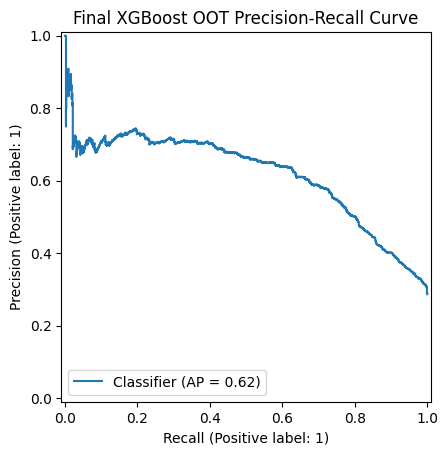

In [43]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    oot_prob
)

plt.title("Final XGBoost OOT Precision-Recall Curve")
plt.show()

OOT Brier score: 0.1652


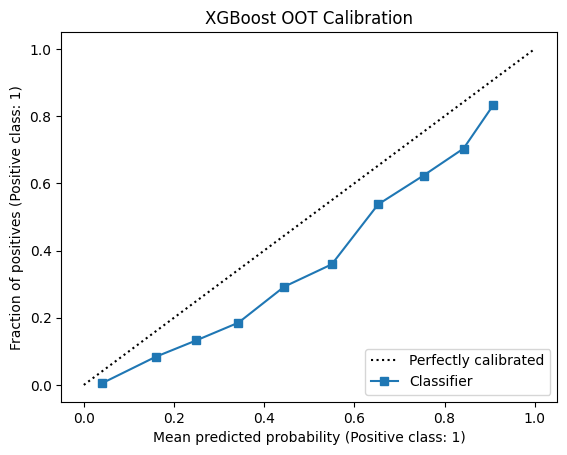

In [44]:
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

print(
    "OOT Brier score:",
    round(
        brier_score_loss(y_test, oot_prob),
        4
    )
)

CalibrationDisplay.from_predictions(
    y_test,
    oot_prob,
    n_bins=10
)

plt.title("XGBoost OOT Calibration")
plt.show()

In [45]:
REPORT_PATH = "../datamart/gold/monitoring/monitoring_report.json"

with open(REPORT_PATH, "r") as f:
    monitoring_report = json.load(f)

feature_psi = (
    monitoring_report["stability_metrics"]
    ["all_numeric_feature_psi"]
)

psi_df = pd.DataFrame([
    {
        "feature": feature,
        "psi": values["psi"]
    }
    for feature, values in feature_psi.items()
    if values["psi"] is not None
])

# Keep only top 10 drifting features
top_psi = (
    psi_df
    .sort_values("psi", ascending=False)
    .head(10)
    .sort_values("psi")
)

display(top_psi)

,feature,psi
42,fe_20_3m_avg,11.431517
36,fe_14_3m_avg,11.442339
27,fe_5_3m_avg,12.432289
26,fe_4_3m_avg,12.434931
24,fe_2_3m_avg,12.440247
32,fe_10_3m_avg,12.440251
29,fe_7_3m_avg,12.442903
30,fe_8_3m_avg,12.442907
31,fe_9_3m_avg,12.442921
22,clickstream_months_available,15.604398


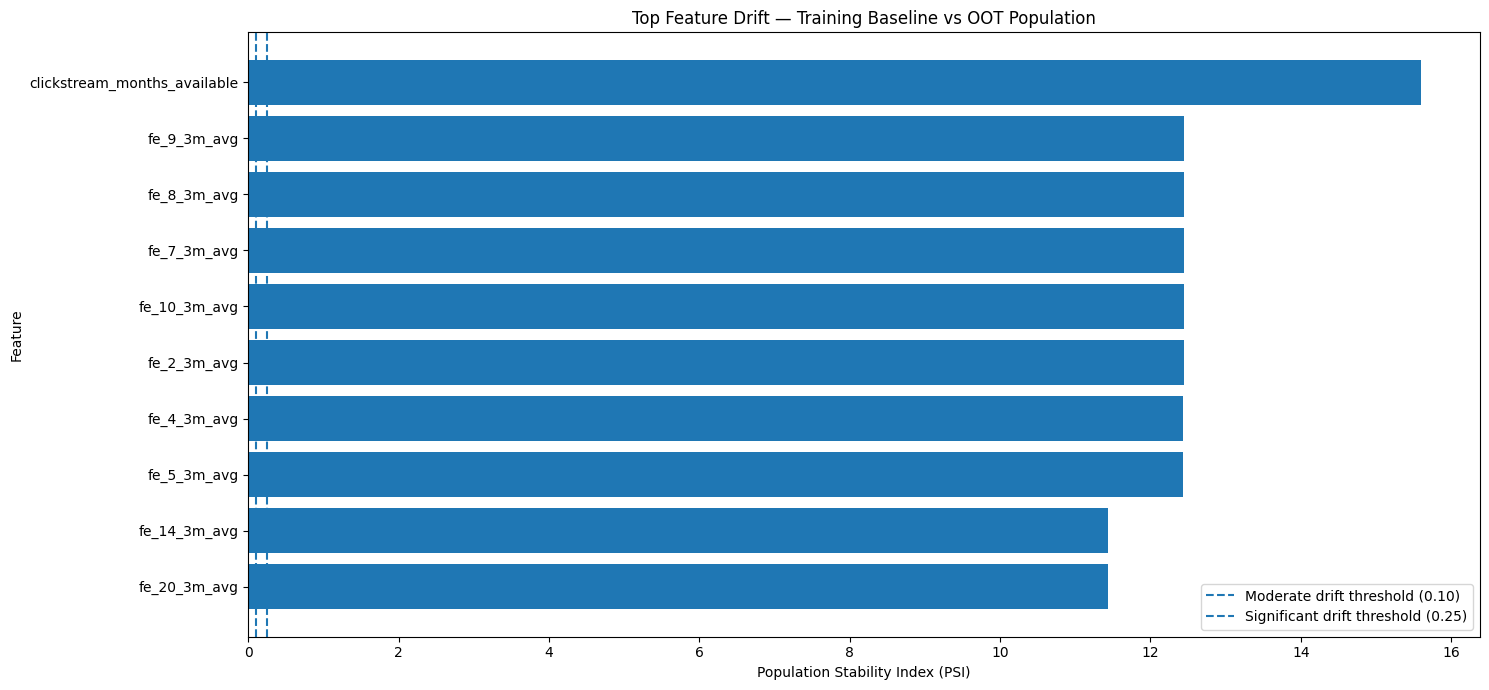

In [50]:
plt.figure(figsize=(15, 7))

plt.barh(
    top_psi["feature"],
    top_psi["psi"]
)

# Professor's PSI thresholds
plt.axvline(
    0.1,
    linestyle="--",
    label="Moderate drift threshold (0.10)"
)

plt.axvline(
    0.25,
    linestyle="--",
    label="Significant drift threshold (0.25)"
)

plt.xlabel("Population Stability Index (PSI)")
plt.ylabel("Feature")
plt.title("Top Feature Drift — Training Baseline vs OOT Population")

plt.legend()
plt.tight_layout()
plt.show()

In [51]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Use the finalized model and untouched OOT population
result = permutation_importance(
    final_pipeline,
    X_test,
    y_test,
    scoring="average_precision",   # PR-AUC
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std
})

importance_df = (
    importance_df
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

display(importance_df.head(20).round(4))

,feature,importance_mean,importance_std
0,Interest_Rate,0.0588,0.0113
1,Outstanding_Debt,0.0503,0.0079
2,Changed_Credit_Limit,0.0391,0.0037
3,Payment_Behaviour,0.0204,0.0034
4,Credit_History_Age_Months,0.0177,0.0048
5,Delay_from_due_date,0.0135,0.0026
6,EMI_to_Income_Ratio,0.0097,0.0031
7,Num_Credit_Card,0.0078,0.0027
8,Num_of_Delayed_Payment,0.0067,0.0020
9,Num_Bank_Accounts,0.0027,0.0026


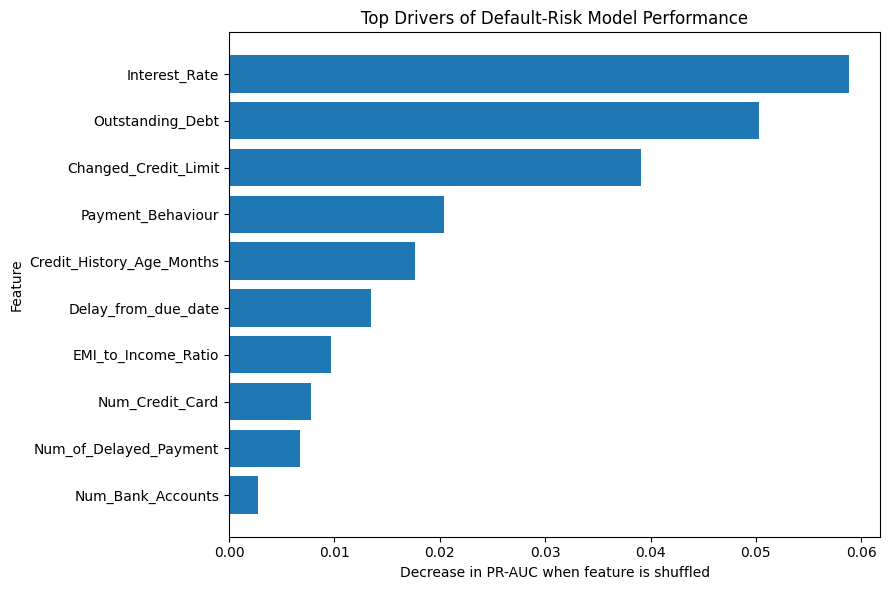

In [56]:
top_features = (
    importance_df
    .head(10)
    .sort_values("importance_mean")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["importance_mean"]
)

plt.xlabel("Decrease in PR-AUC when feature is shuffled")
plt.ylabel("Feature")
plt.title("Top Drivers of Default-Risk Model Performance")

plt.tight_layout()
plt.show()

In [54]:
def feature_group(feature):

    if feature.startswith("fe_") or feature in [
        "clickstream_months_available",
        "has_clickstream_history"
    ]:
        return "Clickstream behaviour"

    elif feature in [
        "Num_Fin_Pdts",
        "Repayment_Ability",
        "Loan_Extent"
    ]:
        return "Cross-team engineered features"

    elif feature in [
        "Debt_to_Income_Ratio",
        "EMI_to_Income_Ratio",
        "Credit_History_Age_Months"
    ]:
        return "Engineered financial ratios"

    elif feature in [
        "Age",
        "Occupation"
    ]:
        return "Customer attributes"

    else:
        return "Credit & financial profile"


grouped_importance = (
    importance_df
    .assign(group=importance_df["feature"].apply(feature_group))
    .groupby("group", as_index=False)["importance_mean"]
    .sum()
    .sort_values("importance_mean", ascending=False)
)

display(grouped_importance.round(4))

,group,importance_mean
1,Credit & financial profile,0.2037
4,Engineered financial ratios,0.0269
0,Clickstream behaviour,0.0000
2,Cross-team engineered features,-0.0002
3,Customer attributes,-0.0030


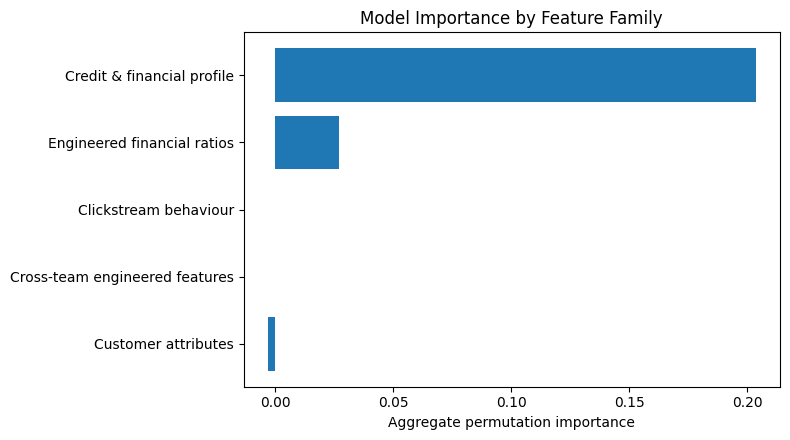

In [55]:
plot_df = grouped_importance.sort_values("importance_mean")

plt.figure(figsize=(8, 4.5))

plt.barh(
    plot_df["group"],
    plot_df["importance_mean"]
)

plt.xlabel("Aggregate permutation importance")
plt.title("Model Importance by Feature Family")

plt.tight_layout()
plt.show()

,month,rows,roc_auc,pr_auc,recall,f1
0,2024-07,505,0.828,0.671,0.703,0.634
1,2024-08,543,0.793,0.614,0.681,0.610
2,2024-09,493,0.817,0.667,0.718,0.659
3,2024-10,456,0.807,0.567,0.723,0.645
4,2024-11,488,0.815,0.626,0.774,0.654
5,2024-12,515,0.838,0.639,0.707,0.667
6,2025-01,526,0.787,0.533,0.695,0.605


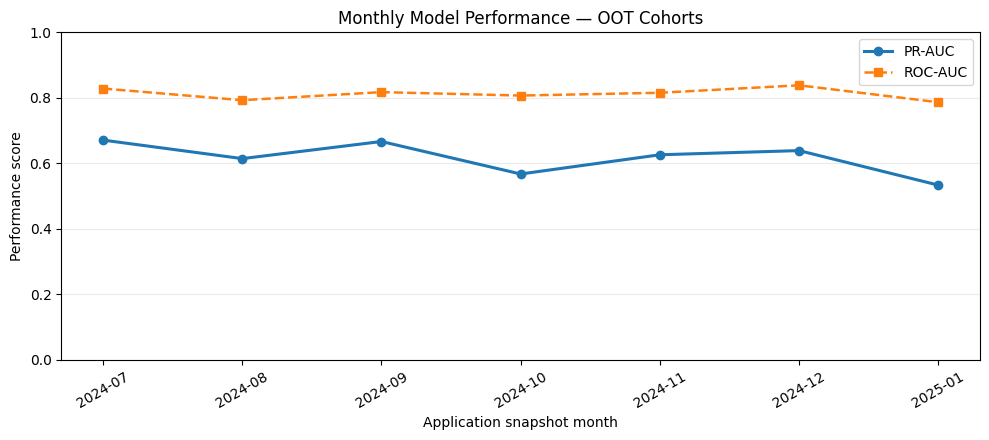

Saved chart to: ../datamart/gold/monitoring/monthly_model_performance.png


In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Locate existing monitoring report
report_path = Path("datamart/gold/monitoring/monitoring_report.json")

if not report_path.exists():
    report_path = Path("../datamart/gold/monitoring/monitoring_report.json")

with open(report_path) as f:
    report = json.load(f)

# Convert monthly results into a table
monthly_df = pd.DataFrame(report["monthly_performance"])
monthly_df = monthly_df.sort_values("month")

display(
    monthly_df[
        ["month", "rows", "roc_auc", "pr_auc", "recall", "f1"]
    ].round(3)
)

# Plot monthly predictive performance
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    monthly_df["month"],
    monthly_df["pr_auc"],
    marker="o",
    linewidth=2.2,
    label="PR-AUC"
)

ax.plot(
    monthly_df["month"],
    monthly_df["roc_auc"],
    marker="s",
    linewidth=1.8,
    linestyle="--",
    label="ROC-AUC"
)

ax.set_title("Monthly Model Performance — OOT Cohorts")
ax.set_ylabel("Performance score")
ax.set_xlabel("Application snapshot month")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
ax.legend()
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

# Save for PowerPoint
output_path = report_path.parent / "monthly_model_performance.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")

plt.show()

print("Saved chart to:", output_path)

Working directory: /Users/yuzhepang/Desktop/SMU/Aug26/MLE/Assignment_2
Loading monitoring inputs...
Prediction rows: 3526
Rows with matured labels: 3526

Baseline rows: 8974
Current rows: 3526

=== MODEL MONITORING ===
Monitoring status: REVIEW_REQUIRED

Performance:
roc_auc: 0.8125
pr_auc: 0.6114
accuracy: 0.7683
precision: 0.5777
recall: 0.7132
f1: 0.6383
brier_score: 0.1623

Model score PSI: 0.2183 - moderate_drift
Moderate drift features: 0
Significant drift features: 21

Top drift features:
clickstream_months_available : 15.6044 - significant_drift
fe_9_3m_avg : 12.4429 - significant_drift
fe_8_3m_avg : 12.4429 - significant_drift
fe_7_3m_avg : 12.4429 - significant_drift
fe_10_3m_avg : 12.4403 - significant_drift

Saved monitoring report to: datamart/gold/monitoring/monitoring_report.json
Baseline rows: 8974
OOT rows: 3526
Recalculated overall PSI: 0.2183
Existing monitoring PSI: 0.2183


,month,rows,model_score_psi
0,2024-07,505,0.1808
1,2024-08,543,0.2088
2,2024-09,493,0.2340
3,2024-10,456,0.2551
4,2024-11,488,0.3189
5,2024-12,515,0.2249
6,2025-01,526,0.2771


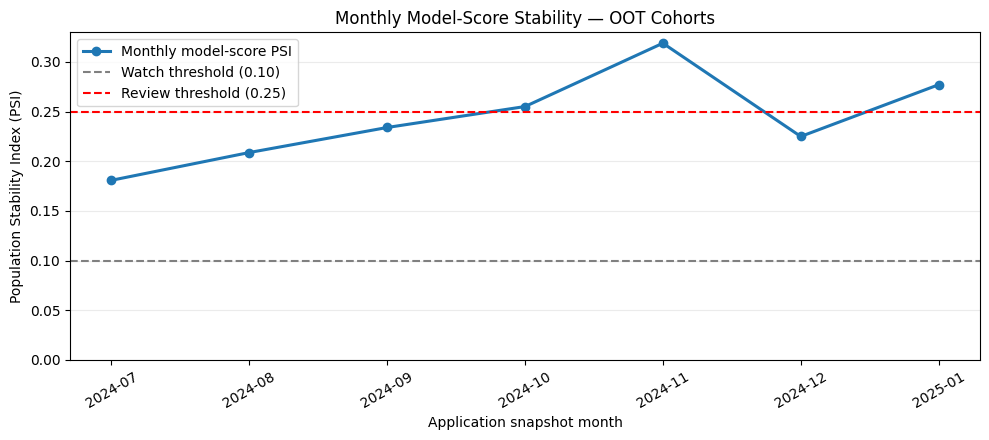

In [4]:
import os
import sys
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Locate project
ROOT = Path.cwd()
if not (ROOT / "scripts/model_monitoring.py").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))

# Ensure relative paths resolve from Assignment_2
os.chdir(ROOT)

print("Working directory:", os.getcwd())

from scripts.model_monitoring import calculate_psi

# 2. Load saved production model and Gold features
model = joblib.load(
    ROOT / "model_bank/xgboost_pipeline.joblib"
)

with open(ROOT / "model_bank/model_metadata.json") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]

features = pd.read_parquet(
    ROOT / "datamart/gold/feature_store/gold_feature_store.parquet"
)

features["snapshot_date"] = pd.to_datetime(
    features["snapshot_date"]
)

# 3. Use the original temporal split
oot_start = pd.Timestamp("2024-07-01")

baseline = features[
    features["snapshot_date"] < oot_start
].copy()

oot = features[
    features["snapshot_date"] >= oot_start
].copy()

print("Baseline rows:", len(baseline))
print("OOT rows:", len(oot))

# 4. Score both populations with the SAME saved model
baseline_scores = model.predict_proba(
    baseline[feature_columns]
)[:, 1]

oot["model_score"] = model.predict_proba(
    oot[feature_columns]
)[:, 1]

# 5. Check that overall PSI matches existing monitoring
overall_psi = calculate_psi(
    baseline_scores,
    oot["model_score"].to_numpy()
)

with open(
    ROOT / "datamart/gold/monitoring/monitoring_report.json"
) as f:
    report = json.load(f)

reported_psi = report["stability_metrics"]["model_score_psi"]["psi"]

print("Recalculated overall PSI:", round(overall_psi, 4))
print("Existing monitoring PSI:", round(reported_psi, 4))

if abs(overall_psi - reported_psi) > 0.01:
    raise ValueError(
        "PSI mismatch: check baseline selection and scoring "
        "against model_monitoring.py before plotting."
    )

# 6. Compute PSI for each OOT month
oot["month"] = oot["snapshot_date"].dt.to_period("M").astype(str)

monthly_psi_results = []

for month, group in oot.groupby("month"):

    month_scores = group["model_score"].to_numpy()

    psi = calculate_psi(
        baseline_scores,
        month_scores
    )

    monthly_psi_results.append({
        "month": month,
        "rows": len(group),
        "model_score_psi": float(psi)
    })

monthly_psi_df = pd.DataFrame(monthly_psi_results)
monthly_psi_df = monthly_psi_df.sort_values("month")

display(monthly_psi_df.round(4))

# 7. Plot
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    monthly_psi_df["month"],
    monthly_psi_df["model_score_psi"],
    marker="o",
    linewidth=2.2,
    label="Monthly model-score PSI"
)

ax.axhline(
    0.10,
    linestyle="--",
    color="gray",
    label="Watch threshold (0.10)"
)

ax.axhline(
    0.25,
    linestyle="--",
    color="red",
    label="Review threshold (0.25)"
)

ax.set_title("Monthly Model-Score Stability — OOT Cohorts")
ax.set_xlabel("Application snapshot month")
ax.set_ylabel("Population Stability Index (PSI)")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

output_dir = ROOT / "datamart/gold/monitoring"

plt.savefig(
    output_dir / "monthly_model_score_psi.png",
    dpi=200,
    bbox_inches="tight"
)

monthly_psi_df.to_csv(
    output_dir / "monthly_model_score_psi.csv",
    index=False
)

plt.show()